# 01 - Exploratory Data Analysis: LPU campus parking occupancy

**Goal.** Understand the occupancy time series before modelling: distributions, daily/weekly patterns, relationships between variables, missing data, outliers, class imbalance and how the chronological train/validation/test split is composed.

> **Data caveat.** `lpu_timeseries.csv` is *simulated* by `data_pipeline/generator.py` (12 zones, 5-minute cadence, 56 days) until real detector counts are logged. Patterns below reflect the generator's assumptions (timetable, bell surges, exam week, fest, rain days), not measured LPU behaviour. Run from the repository root.

In [1]:
import warnings; warnings.filterwarnings('ignore')
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style='whitegrid', context='notebook')
df = pd.read_csv('data/processed/lpu_timeseries.csv', parse_dates=['timestamp'])
df['occ'] = df.vehicle_count / df.operational_capacity
df['hour'] = df.timestamp.dt.hour; df['dow'] = df.timestamp.dt.dayofweek
df['weekend'] = df.dow >= 5; df['date'] = df.timestamp.dt.date
print(df.shape, df.timestamp.min(), '->', df.timestamp.max())
df.head()

(193536, 14) 2026-09-01 00:00:00 -> 2026-10-26 23:55:00


,timestamp,zone_id,vehicle_count,operational_capacity,is_exam_day,is_campus_event,is_class_transition,camera_status,camera_age_seconds,occ,hour,dow,weekend,date
0,2026-09-01,ZONE_ARCH,0,120,0,0,0,live,33.0,0.000000,0,1,False,2026-09-01
1,2026-09-01,ZONE_BH2,115,135,0,0,0,live,11.0,0.851852,0,1,False,2026-09-01
2,2026-09-01,ZONE_BLOCK1,4,140,0,0,0,live,32.0,0.028571,0,1,False,2026-09-01
3,2026-09-01,ZONE_BLOCK57,0,185,0,0,0,live,31.0,0.000000,0,1,False,2026-09-01
4,2026-09-01,ZONE_CENTRAL_MESS2,3,110,0,0,0,live,16.0,0.027273,0,1,False,2026-09-01


## 1. Dataset characteristics and attributes

In [2]:
cap = df.groupby('zone_id').operational_capacity.first().rename('capacity')
summary = df.groupby('zone_id').agg(mean_cars=('vehicle_count','mean'), max_cars=('vehicle_count','max'),
                                    mean_occ=('occ','mean'), p95_occ=('occ', lambda s: s.quantile(.95))).join(cap)
display(summary.round(2))
print('rows per zone:', df.groupby('zone_id').size().unique(), '| cadence:', df[df.zone_id==df.zone_id.iloc[0]].timestamp.diff().mode()[0])

,mean_cars,max_cars,mean_occ,p95_occ,capacity
zone_id,,,,,
ZONE_ARCH,34.72,138,0.29,0.93,120
ZONE_BH2,89.57,150,0.66,1.01,135
ZONE_BLOCK1,41.65,161,0.30,0.96,140
ZONE_BLOCK57,54.18,210,0.29,0.92,185
ZONE_CENTRAL_MESS2,35.77,124,0.33,0.92,110
ZONE_GH5,106.20,177,0.66,1.01,160
ZONE_LAW,38.04,148,0.29,0.92,130
ZONE_MAINGATE,86.48,276,0.36,0.94,240
ZONE_MAINPARK_NORTH,92.01,368,0.29,0.94,320


rows per zone: [16128] | cadence: 0 days 00:05:00


## 2. Data quality: missing values, duplicates, sensor status, outliers

In [3]:
print('missing values per column:\n', df.isna().sum()[lambda s: s>0] if df.isna().any().any() else 'none')
print('duplicate (timestamp, zone) rows:', df.duplicated(['timestamp','zone_id']).sum())
print('camera_status counts:\n', df.camera_status.value_counts())
print('offline rows by zone:\n', df[df.camera_status!='live'].groupby('zone_id').size())
over = df[df.occ > 1]
print(f'rows above 100% of operational capacity: {len(over)} ({len(over)/len(df):.2%}); max occupancy ratio {df.occ.max():.2f}')
print('negative counts:', (df.vehicle_count<0).sum())

missing values per column:
 none
duplicate (timestamp, zone) rows: 0
camera_status counts:
 camera_status
live       193517
offline        19
Name: count, dtype: int64
offline rows by zone:
 zone_id
ZONE_BLOCK1    19
dtype: int64
rows above 100% of operational capacity: 5235 (2.70%); max occupancy ratio 1.15
negative counts: 0


**Reading.** There are no gaps or duplicates (the series is complete by construction). Camera outages exist only for `ZONE_BLOCK1` (one 90-minute window) - the dashboard must handle stale cameras even though the training data barely contains them. A small share of rows exceeds 100% of the operational capacity (overflow / double parking): they are plausible, not errors, so they are kept rather than clipped. Real logged data will need genuine gap and outlier handling.

## 3. Distributions

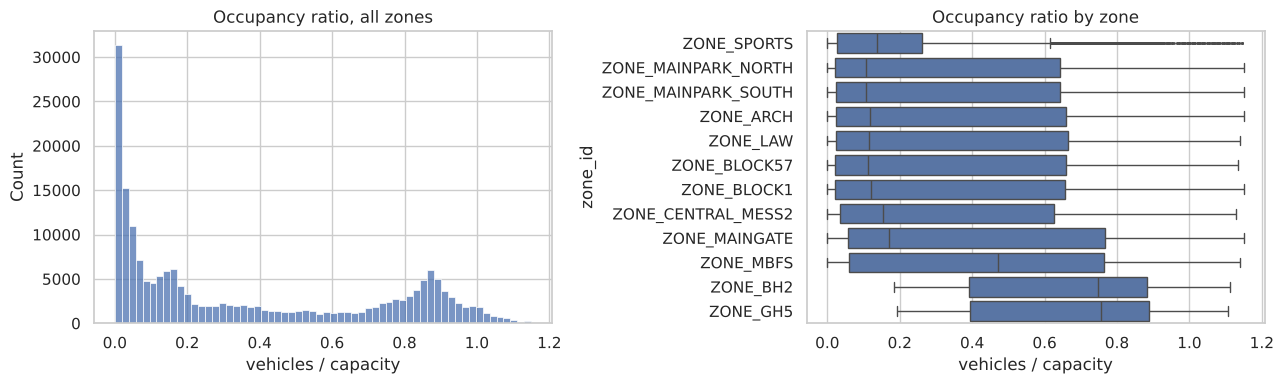

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df.occ, bins=60, ax=ax[0]); ax[0].set(title='Occupancy ratio, all zones', xlabel='vehicles / capacity')
order = summary.sort_values('mean_occ').index
sns.boxplot(data=df, y='zone_id', x='occ', order=order, ax=ax[1], fliersize=1); ax[1].set(title='Occupancy ratio by zone', xlabel='vehicles / capacity')
plt.tight_layout(); plt.show()

**Reading.** Occupancy is strongly **bimodal**: lots are mostly nearly empty (nights, weekends) or nearly full (class hours). Hostel and dining zones sit high overnight/meal-times, academic zones during the day. A single mean-based model would be poor here, which is why zone identity and time-of-day features matter.

## 4. Daily and weekly patterns

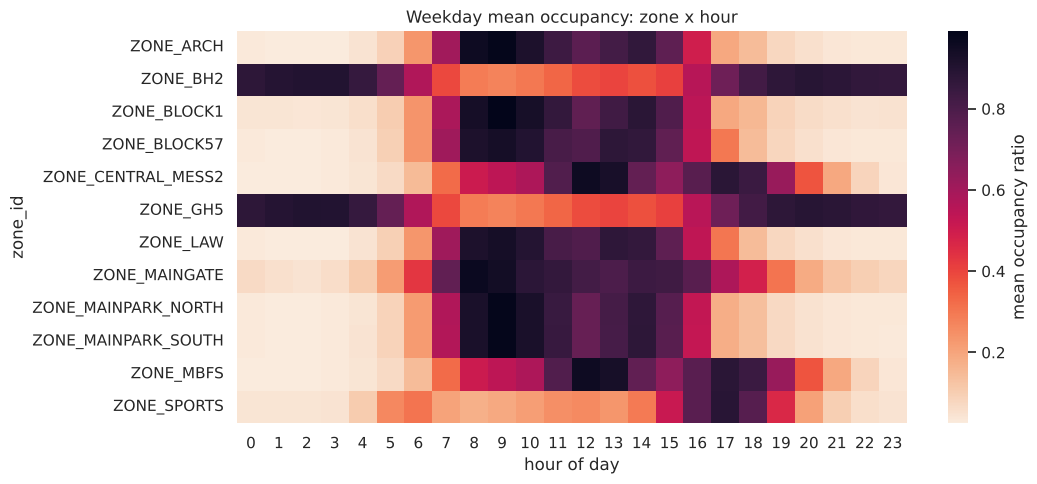

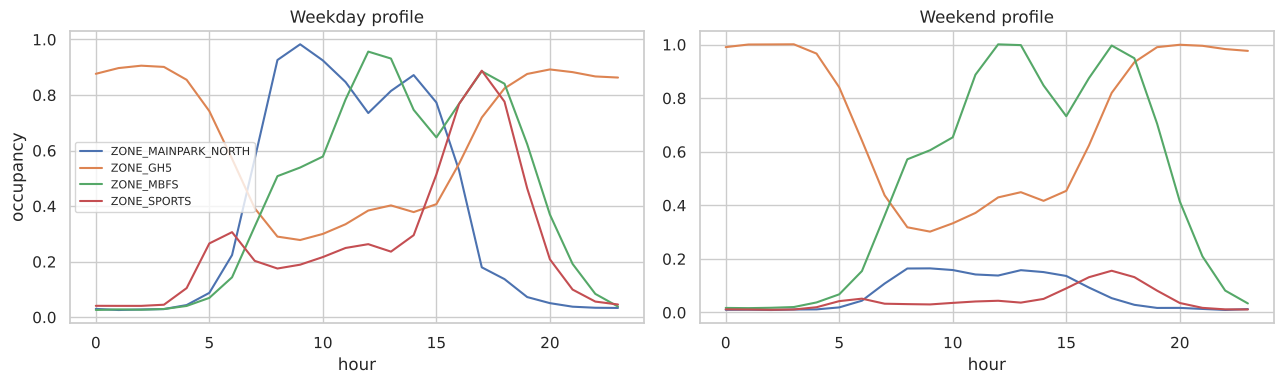

In [5]:
wk = df[~df.weekend].groupby(['zone_id','hour']).occ.mean().unstack()
fig, ax = plt.subplots(figsize=(11, 5))
sns.heatmap(wk, cmap='rocket_r', ax=ax, cbar_kws={'label':'mean occupancy ratio'}); ax.set(title='Weekday mean occupancy: zone x hour', xlabel='hour of day')
plt.tight_layout(); plt.show()
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for z in ['ZONE_MAINPARK_NORTH','ZONE_GH5','ZONE_MBFS','ZONE_SPORTS']:
    d = df[(df.zone_id==z)]
    ax[0].plot(d[~d.weekend].groupby('hour').occ.mean(), label=z)
    ax[1].plot(d[d.weekend].groupby('hour').occ.mean(), label=z)
ax[0].set(title='Weekday profile', xlabel='hour', ylabel='occupancy'); ax[1].set(title='Weekend profile', xlabel='hour'); ax[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Reading.** Four archetypes: *academic* (peak ~09-16, collapse at weekends), *dining* (lunch ~12-14 and dinner ~17-19 peaks), *hostel* (high overnight, dip during class hours, weekends stay busy) and *sports* (evening peak). Weekends flatten academic lots to ~18% of weekday levels. Different archetypes need different forecasts, so a single global profile (e.g. an all-zone seasonal mean) fails.

## 5. Special regimes: exam week, campus event, rain

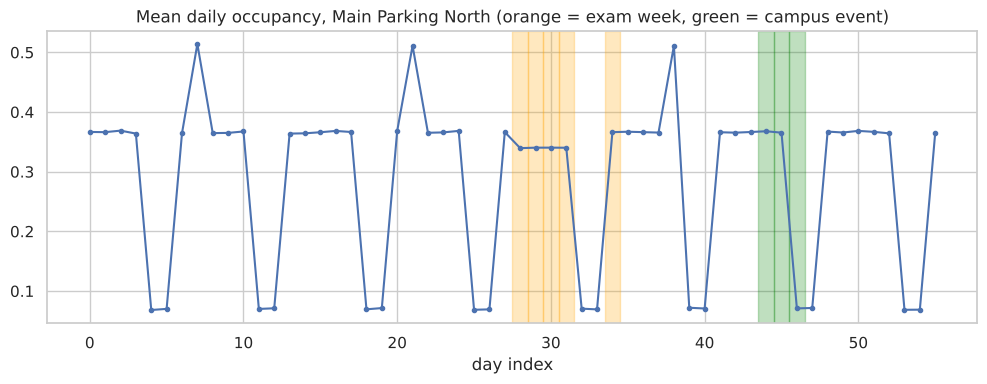

{0: 0.364, 1: 0.408} | event: {0: 0.363, 1: 0.486}


In [6]:
d = df.copy(); d['day'] = (d.timestamp - d.timestamp.min()).dt.days
flags = d.groupby('day').agg(exam=('is_exam_day','max'), event=('is_campus_event','max'))
mp = d[d.zone_id=='ZONE_MAINPARK_NORTH'].groupby('day').occ.mean()
fig, ax = plt.subplots(figsize=(12, 3.8)); ax.plot(mp.index, mp.values, marker='o', ms=3)
for dd in flags.index[flags.exam==1]: ax.axvspan(dd-.5, dd+.5, color='orange', alpha=.25)
for dd in flags.index[flags.event==1]: ax.axvspan(dd-.5, dd+.5, color='green', alpha=.25)
ax.set(title='Mean daily occupancy, Main Parking North (orange = exam week, green = campus event)', xlabel='day index'); plt.show()
print(df.groupby('is_exam_day').occ.mean().round(3).to_dict(), '| event:', df.groupby('is_campus_event').occ.mean().round(3).to_dict())

**Reading.** Exam week lifts weekday occupancy of the computing lots to ~94% through the exam windows; the fest increases load at the gate, Block 1 and sports lots. These regimes are rare (about 6 of 56 days and 2 of 56 days), so a model sees few examples - and, importantly, with a chronological split they fall in the **train/validation** periods, leaving the test period regime-free (see section 8).

## 6. Temporal dependence and relationships between variables

,autocorrelation
5 min,0.992
15 min,0.983
30 min,0.961
60 min,0.906
180 min,0.592
360 min,0.142
720 min,-0.496
1440 min,0.759


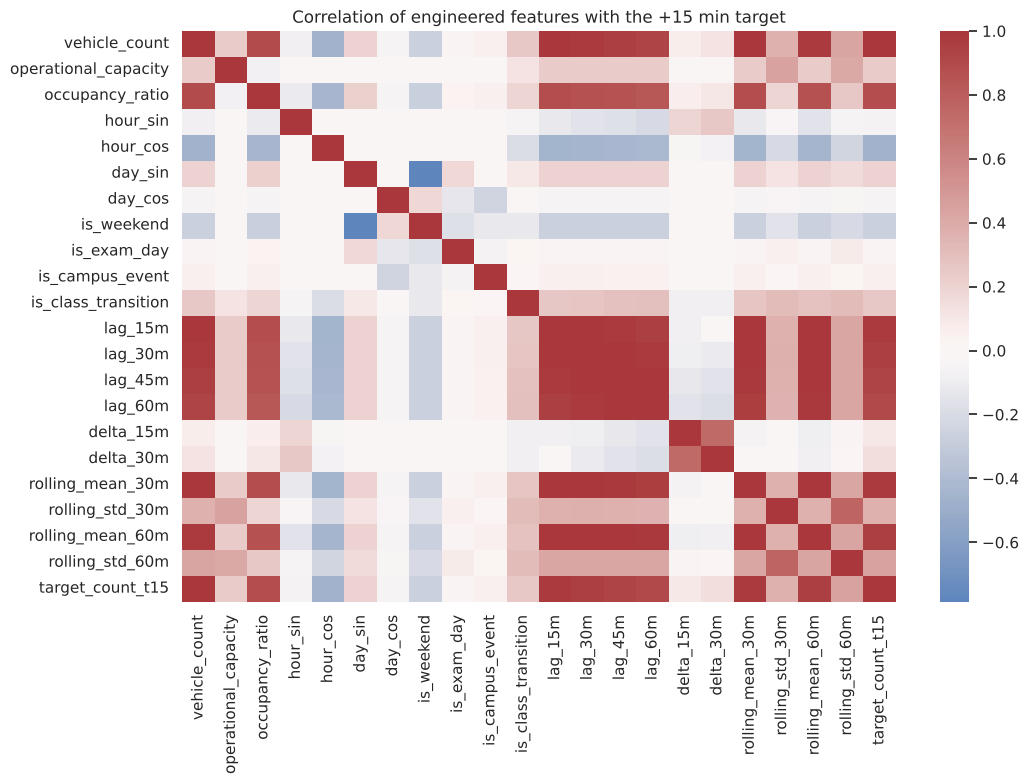

vehicle_count       0.988
rolling_mean_30m    0.974
lag_15m             0.973
rolling_mean_60m    0.957
lag_30m             0.954
lag_45m             0.931
lag_60m             0.905
occupancy_ratio     0.884
Name: target_count_t15, dtype: float64


In [7]:
z = df[df.zone_id=='ZONE_MAINPARK_NORTH'].set_index('timestamp').vehicle_count
lags = [1,3,6,12,36,72,144,288]  # 5 min ... 24 h
ac = pd.Series({f'{l*5} min': z.autocorr(l) for l in lags})
display(ac.round(3).to_frame('autocorrelation'))
feat = pd.read_csv('data/processed/lpu_timeseries.csv', parse_dates=['timestamp'])
from features.feature_pipeline import TimeSeriesFeaturePipeline, FEATURE_COLS
f = TimeSeriesFeaturePipeline().transform_zone_series(feat).dropna()
cols = [c for c in FEATURE_COLS if c not in ('zone_code',)] + ['target_count_t15']
fig, ax = plt.subplots(figsize=(11, 8)); sns.heatmap(f[cols].corr(), cmap='vlag', center=0, ax=ax, annot=False)
ax.set(title='Correlation of engineered features with the +15 min target'); plt.tight_layout(); plt.show()
print(f[cols].corr()['target_count_t15'].drop('target_count_t15').sort_values(ascending=False).round(3).head(8))

**Reading.** Occupancy is extremely autocorrelated at short lags (near 1 at 5-60 min) and decays across the day, with a secondary bump at 24 h (daily seasonality). Therefore *the current count and its recent lags explain most of the +15 min target*, and the correlation heatmap shows heavy multicollinearity between `vehicle_count`, the lags and the rolling means (expected for a lagged series). That is a reason to prefer tree ensembles (robust to collinearity) over linear models, and it explains why persistence is a strong baseline that the model has to beat by modelling **changes**, not levels.

## 7. Class imbalance of the saturation target (occupancy >= 90% at +15 min)

In [8]:
sat = (f.target_count_t15 >= 0.9*f.operational_capacity).astype(int)
print(f'saturated share overall: {sat.mean():.2%}   (imbalance ratio free:saturated = {(1-sat.mean())/sat.mean():.1f}:1)')
print((sat.groupby(f.zone_id).mean()*100).round(1).sort_values().to_string())

saturated share overall: 10.21%   (imbalance ratio free:saturated = 8.8:1)
zone_id
ZONE_SPORTS             1.2
ZONE_CENTRAL_MESS2      6.9
ZONE_BLOCK57            7.0
ZONE_LAW                7.1
ZONE_MAINGATE           7.4
ZONE_ARCH               8.9
ZONE_MAINPARK_NORTH     9.6
ZONE_MAINPARK_SOUTH     9.7
ZONE_BLOCK1            10.8
ZONE_MBFS              12.7
ZONE_BH2               20.1
ZONE_GH5               21.1


**Reading.** Only about one observation in ten is saturated, and the share varies hugely by zone (hostel lots saturate overnight, academic lots in class hours). Plain accuracy would be ~90% for a model that never predicts saturation, so the classifier is judged on **precision/recall/PR-AUC** and trained with `scale_pos_weight` + probability calibration (see `experiments/error_analysis.py`).

## 8. How the data is split (no leakage)

In [9]:
from models.data_prep import load_splits
sp = load_splits()
rows = []
for k, s in sp.items():
    t = s.meta.timestamp
    rows.append({'split': k, 'rows': len(s.X), 'from': t.min(), 'to': t.max(), 'days': round((t.max()-t.min()).total_seconds()/86400,1),
                 'exam rows': int(s.X.is_exam_day.sum()), 'event rows': int(s.X.is_campus_event.sum()),
                 'saturated share': round(float(s.y['SAT15'].mean()),3)})
display(pd.DataFrame(rows))

,split,rows,from,to,days,exam rows,event rows,saturated share
0,train,135192,2026-09-01 01:00:00,2026-10-10 03:45:00,39.1,13836,0,0.107
1,val,28608,2026-10-10 06:45:00,2026-10-18 13:20:00,8.3,0,6924,0.098
2,test,28608,2026-10-18 16:20:00,2026-10-26 22:55:00,8.3,0,0,0.087


**Reading.** The split is chronological (70/15/15) with a 1-hour buffer, and features are built *after* splitting, per zone, so no lag or rolling window crosses a boundary. Consequence worth stating in the report: the exam week lies in the training period and the fest in validation, so the **test period contains neither** and cannot measure performance on those special regimes. Mitigation for the final system: collect real data across a full semester and add a rolling-origin evaluation that holds out an exam week.

## Summary of findings
1. Complete 5-minute series for 12 zones; the only quality issues are one camera outage and a small share of >100% rows.
2. Occupancy is bimodal and zone-archetype dependent (academic, dining, hostel, sports) - zone and time features are essential.
3. Very high short-lag autocorrelation: persistence is a strong baseline and collinear lag features favour tree ensembles.
4. The saturation target is imbalanced (~1 in 10) and zone dependent - use PR-based metrics and calibration.
5. Special regimes are rare and land outside the test period - a limitation to address with more data.